# Fuzzy c-means clustering with training data

In this notebook, the fuzzy c-means algorithm is tested using signals generated with the Gilmore-akulichev model using the a range of frequencies and intensities. This is carried out to ensure that a single trained algorithm can be used to predict the stability of a range of cavitation signals measured under consistent conditions.

In [1]:
import sys

if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")


import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
%matplotlib inline
sys.path.append("..")
import wavelet_transform.utils.training_data as train
import wavelet_transform.postprocess.plotting as plot

### Set pararmeters for bubble dynamics model
see bubble_dynamics_training_data.py

In [3]:
# Set sampling rate and noise std
sampling_rate = 50e6
std_noise = 0.05

# Set length of data to keep
sample_time = 20 / 1.5e6
data_len = int(sample_time * sampling_rate)

# Parameters for the wavelet transform
wavelet = "db4"
levels = None  # max level for the transform
mode = "symmetric"
use_min_entropy = True
min_level = 3

### Training data

Run bubble dynamics over a range of frequencies and intensities to generate a larger array of training data.

In [4]:
wpt_df = train.generate_training_data_with_wavelet(
    wavelet, sampling_rate, levels, mode, std_noise, 
    data_len, min_entropy=use_min_entropy, min_level=min_level
)

### Training

Train fuzzy c-means on the generated data

In [5]:
from sklearn.preprocessing import StandardScaler
import skfuzzy as fuzz


def train_c_means(wpt_df, no_clusters, classifying_metrics, m):
    # Get data
    data_train = wpt_df[classifying_metrics]

    # Standardise data
    scaler = StandardScaler()
    data_train_normalised = scaler.fit_transform(data_train)

    # Fuzzy C-Means clustering
    cntr, u, u0, d, jm, p, fpc = fuzz.cluster.cmeans(
        data_train_normalised.T,
        c=no_clusters,
        m=m,
        error=1e-6,
        maxiter=100,
    )
    # print("number of iterations:", p)
    # Cluster centres
    centers = scaler.inverse_transform(cntr)
    # print("centers:", centers)
    # Membership matrix
    membership_matrix = u.T

    # Hard cluster assignments
    labels = np.argmax(membership_matrix, axis=1)
    # for i in range(no_clusters):
    #     print(f"label {i} count:", list(labels).count(i))

    # membership_results = pd.DataFrame()
    # for i, membership in enumerate(membership_matrix):
    #     membership_results.loc[i, "hard assignment"] = labels[i]
    #     for j in range(no_clusters):
    #         membership_results.loc[i, f"membership {j}"] = membership[j]

    # membership_results.head()
    return data_train, labels, data_train_normalised, centers, cntr, scaler

In [15]:
# Parameters for Fuzzy C-means
no_clusters = 5
m = 2
classifying_metrics = ["log average energy", "spectral entropy", "kurtosis"]

data_train, labels, data_train_normalised, centers, cntr, scaler = train_c_means(
    wpt_df, no_clusters, classifying_metrics, m
    )

### Clustering results

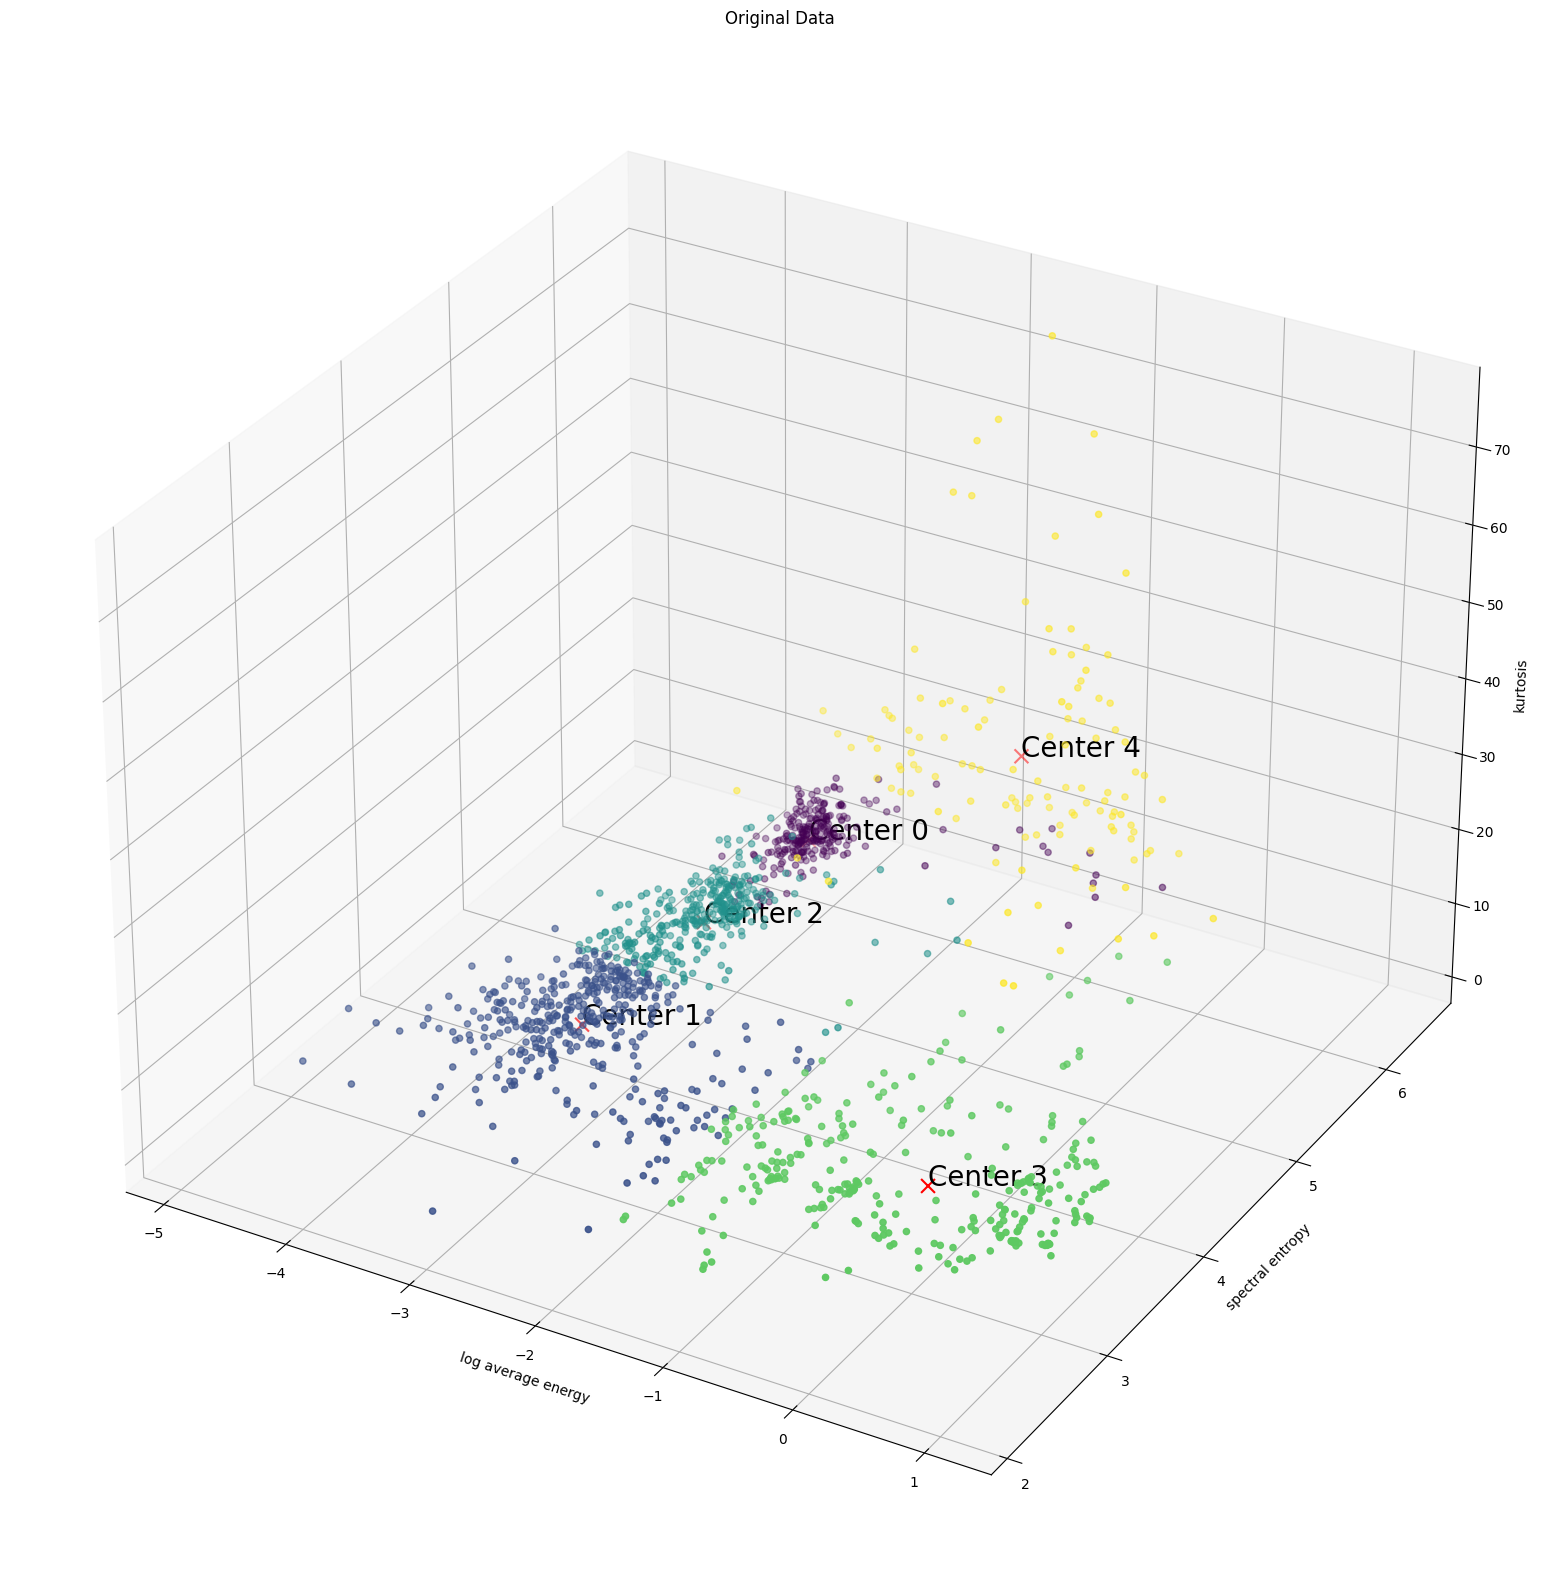

In [16]:
fig = plt.figure(figsize=(20, 20))
ax = fig.add_subplot(111, projection="3d")

title = "Original Data"

data_scatter = data_train.values.tolist()
centers_scatter = centers
color_map_labels = labels

# Plot data points
data_plot = ax.scatter(
    [point[0] for point in data_scatter],
    [point[1] for point in data_scatter],
    [point[2] for point in data_scatter],
    c=color_map_labels
)

# Plot cluster centers after data points
center_plot = ax.scatter(
    centers_scatter[:, 0],
    centers_scatter[:, 1],
    centers_scatter[:, 2],
    c="red",
    marker="x",
    s=100,
)

# Annotate cluster centers with their positions
for i, center in enumerate(centers_scatter):
    ax.text(center[0], center[1], center[2], f'Center {i}', color='black', fontsize=20)

ax.set_xlabel(data_train.columns[0])
ax.set_ylabel(data_train.columns[1])
ax.set_zlabel(data_train.columns[2])
ax.set_title(title)

plt.show()

### Numerical studies

In [17]:
wavelets = [f"db{i}" for i in range(4, 21)]

In [18]:
run = False
if run is True:
    from sklearn.metrics import silhouette_score
    scores = []

    for wavelet in wavelets:
        print(wavelet)
        wpt_df = train.generate_training_data_with_wavelet(wavelet, sampling_rate, levels, mode, std_noise, data_len)
        _, _labels, _data_train_normalised, *_   = train_c_means(wpt_df, no_clusters=no_clusters, m=m)
        scores.append(silhouette_score(_data_train_normalised, _labels)) 
        
    fig, ax = plt.subplots()
    fig.set_size_inches(15, 7)
    plt.bar(wavelets, scores)
    plt.title("silhouette score vs db order")
    plt.show()

### Classifying new data points

dynamics is inconsistent
clustering works better with fewer levels
need better standardisation of data

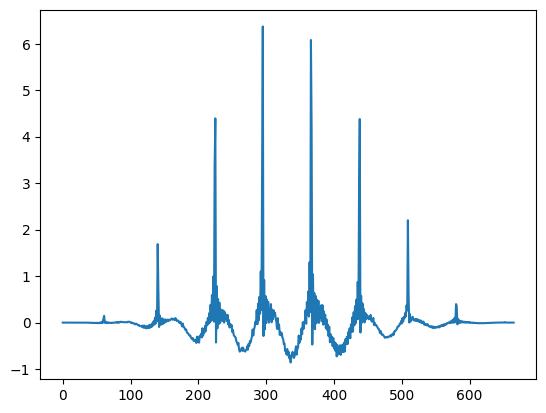

In [29]:
frequency = 7E5
pac = -2E5
R_init = 3e-6

min_energy = 0  # Only nodes with energy at least min_energy * total_energy will be considered

data = train.get_data(R_init, frequency, pac, sampling_rate)
data = (data - np.mean(data)) / np.std(data)
data += np.random.normal(0, std_noise, len(data))
data = data[:data_len]
data *= np.blackman(len(data))

new_wpt_df, new_tr_obj = train.generate_training_data(
    data, 
    levels,
    wavelet, 
    mode,
    min_energy=min_energy,
    include_tr_obj=True,
    min_entropy=True,
    min_level=min_level
)

new_wpt_df.head()

plt.plot(data)
plt.show()

In [30]:
# new_tr_obj.calc_frequencies(sampling_rate)
# plot.heisenberg(new_tr_obj)

In [31]:
# New testing data from signal
new_entry = new_wpt_df[classifying_metrics]

# Standardize the new entry using the same scaler
new_entry_normalized = scaler.transform(new_entry)

# Predict membership using the cluster centers and membership matrix
new_u, *_ = fuzz.cluster.cmeans_predict(
    new_entry_normalized.T,
    cntr,
    m=m,
    error=1e-6,
    maxiter=100,
)

new_membership_matrix = new_u.T
# Convert membership to hard cluster assignment
new_labels = np.argmax(new_u, axis=0)

# Display the predicted results
print("Predicted hard cluster assignment:", new_labels)

membership_results = pd.DataFrame()
for i, membership in enumerate(new_membership_matrix):
    membership_results.loc[i, "hard assignment"] = new_labels[i]
    for j in range(no_clusters):
        membership_results.loc[i, f"membership {j}"] = membership[j]

membership_results

Predicted hard cluster assignment: [3 0 4 4 4 4 4 0]


,hard assignment,membership 0,membership 1,membership 2,membership 3,membership 4
0,3.0,0.104426,0.116874,0.133254,0.548079,0.097368
1,0.0,0.261978,0.133479,0.225660,0.200356,0.178526
2,4.0,0.144401,0.081282,0.132807,0.092877,0.548633
3,4.0,0.268710,0.100398,0.188982,0.102379,0.339531
4,4.0,0.127804,0.064688,0.103966,0.073807,0.629735
5,4.0,0.030904,0.019431,0.027799,0.021008,0.900858
6,4.0,0.111728,0.056248,0.092783,0.059621,0.679620
7,0.0,0.341325,0.115981,0.222731,0.126784,0.193178


### Reconstructing by cluster

Reconstructed nodes by group:


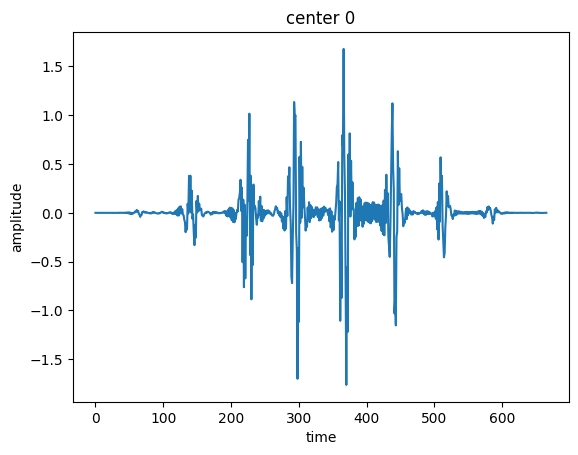

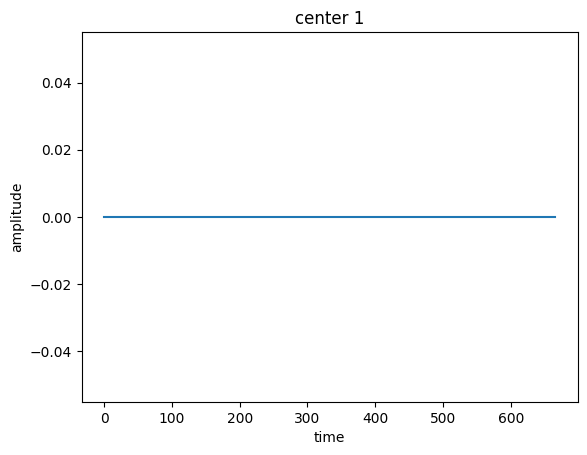

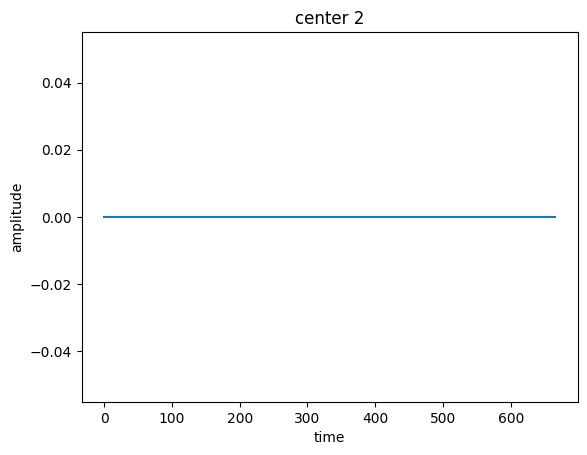

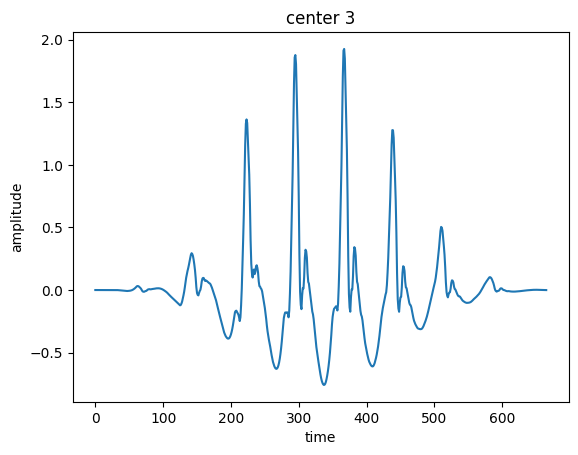

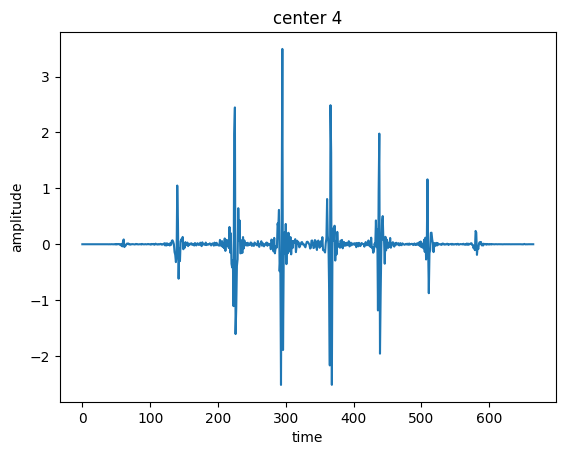

In [32]:
# Sum all reconstructions belonging to the same group
plot.plot_reconstructions_by_group(new_tr_obj, new_labels, no_clusters)

### Plot nodes

Plot each node in the test data set alongside its membership values. Filter by the centre the node is assigned to.

In [33]:
import wavelet_transform.wpt.inverse_transform as inv
run = True
if run is True:
    plot_centres = [2]
    for i, (node, assignment) in enumerate(zip(new_tr_obj.get_leaf_nodes(), new_labels)):
        if assignment in plot_centres:
            rec = inv.inv_dwpt(new_tr_obj, node.level, nodes=node)
            plt.plot(rec)
            plt.title(f"memberships {new_membership_matrix[i]}")
            plt.show()
